# Análisis exploratorio de Common Voice 26.0 (español), clips validados

Este notebook describe el corpus del que sale el subconjunto de evaluación de la tesis. Revisa la
**duración de los clips**, **cuántos clips graba cada hablante** (quiénes concentran el corpus), los
**metadatos demográficos** (género, edad y acento, todos autorreportados), la **estratificación por
acento** con las mismas reglas de `scripts/`, el **texto leído** y, por último, si el
**subconjunto K = 134** se parece al corpus del que sale.

**Alcance:** solo `validated.tsv`, como en el resto del proyecto. `clip_durations.tsv` aporta la duración.
Los conteos del `README.md` del corpus incluyen también clips no validados, así que **no coinciden** con
los de aquí.

**Cómo ejecutarlo:** guárdalo en `Coeficiente-de-McAdams\notebooks\` y ábrelo con el kernel de
`venv-eval`. La celda de configuración busca sola la raíz del repositorio y la carpeta `..\Datos`.

Las celdas de texto separan lo que viene de los datos (**[Dato]**) de la lectura que se hace de ellos
(**[Interpretación]**).

## 1. Configuración y carga

In [1]:
import csv
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, PercentFormatter

%matplotlib inline


def find_repo_root(start):
    """Sube desde `start` hasta encontrar la carpeta con pyproject.toml y scripts/."""
    for folder in [start, *start.parents]:
        if (folder / "pyproject.toml").exists() and (folder / "scripts").is_dir():
            return folder
    raise FileNotFoundError("No se encontró la raíz del repositorio (pyproject.toml + scripts/).")


REPO_ROOT = find_repo_root(Path.cwd().resolve())
DATOS = REPO_ROOT.parent / "Datos"
CORPUS_DIR = (DATOS / "Common Voice Scripted Speech 26.0 - Spanish"
              / "1781723056928-cv-corpus-26.0-2026-06-12-es" / "cv-corpus-26.0-2026-06-12" / "es")
SUBSET_PATH = DATOS / "subset_k134.tsv"   # manifiesto del subconjunto de evaluación
FIG_DIR = DATOS / "figuras" / "corpus"    # aquí se guardan las figuras en PDF
GUARDAR_FIGURAS = True

# Se reutilizan las reglas del pipeline para que el análisis use exactamente
# los mismos estratos y filtros que build_subset.py.
sys.path.insert(0, str(REPO_ROOT / "scripts"))
from build_subset import CLIPS_PER_SPEAKER, MIN_DURATION_MS, STRATA  # noqa: E402
from common_voice_strata import ACCENT_TO_STRATUM, OTRO, SIN_DATO, assign_stratum  # noqa: E402

print("Repositorio:", REPO_ROOT)
print("Corpus:     ", CORPUS_DIR, "| existe:", CORPUS_DIR.exists())
print(f"Filtros del pipeline: duración >= {MIN_DURATION_MS} ms, >= {CLIPS_PER_SPEAKER} clips por hablante")
print("Estratos muestreados:", STRATA)

Repositorio: C:\Users\Daiana\Documents\Proyecto de grado\Coeficiente-de-McAdams
Corpus:      C:\Users\Daiana\Documents\Proyecto de grado\Datos\Common Voice Scripted Speech 26.0 - Spanish\1781723056928-cv-corpus-26.0-2026-06-12-es\cv-corpus-26.0-2026-06-12\es | existe: True
Filtros del pipeline: duración >= 3000 ms, >= 5 clips por hablante
Estratos muestreados: ['mexico', 'andino_pacifico', 'espana_norte', 'rioplatense', 'caribe', 'espana_centro_sur', 'america_central', 'chileno', 'espana_sur', 'sin_dato']


In [2]:
# Estilo de las figuras: colores de la paleta Okabe-Ito (la misma de plot_eer.py),
# texto pequeño y fuentes TrueType en el PDF.
AZUL, NARANJA, VERDE, GRIS = "#0072B2", "#D55E00", "#009E73", "#BBBBBB"
plt.rcParams.update({
    "font.size": 9, "pdf.fonttype": 42, "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "0.92", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
coma = FuncFormatter(lambda x, _: f"{x:g}".replace(".", ","))   # coma decimal en los ejes
pd.set_option("display.max_colwidth", 80)


def guardar(fig, nombre):
    """Guarda la figura en FIG_DIR como PDF si GUARDAR_FIGURAS es True."""
    if GUARDAR_FIGURAS:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{nombre}.pdf", bbox_inches="tight")


def leer_tsv(path, **kwargs):
    """Lee un TSV de Common Voice como texto, sin interpretar comillas (igual que read_tsv_rows)."""
    return pd.read_csv(path, sep="\t", quoting=csv.QUOTE_NONE, dtype=str,
                       keep_default_na=False, encoding="utf-8", **kwargs)

In [3]:
validated = leer_tsv(CORPUS_DIR / "validated.tsv")
durations = leer_tsv(CORPUS_DIR / "clip_durations.tsv").rename(
    columns={"clip": "path", "duration[ms]": "duration_ms"})
# Igual que load_durations: lo que no es un entero se trata como duración desconocida.
durations["duration_ms"] = pd.to_numeric(durations["duration_ms"], errors="coerce").astype("Int64")

df = validated.merge(durations, on="path", how="left", validate="many_to_one")
df["dur_s"] = df["duration_ms"].astype("float") / 1000
df["up_votes"] = df["up_votes"].astype(int)
df["down_votes"] = df["down_votes"].astype(int)
print(df.shape)
df.head(3)

(439225, 15)


,client_id,path,sentence_id,sentence,sentence_domain,up_votes,down_votes,age,gender,accents,variant,locale,segment,duration_ms,dur_s
0,0003b969350f5308dc7347c574bc291834f38fdd92a2863b6059349b4be9738133855f3c49c0...,common_voice_es_19698530.mp3,0e645d113a1374fea443c0302446b5f45c077a7032f58a958cdb13596f6d0c10,Habita en aguas poco profundas y rocosas.,,2,1,thirties,male_masculine,México,,es,,3672,3.672
1,00208480a9ee22afc6b2173b01cb475b1fea9fe4325309394ab3e6ff2c2bd0950efdfaf22d91...,common_voice_es_43172375.mp3,563cf98952e04b2e91bad22f3014971c5d8e2d9b6b4752f6aa073563ed4a6ea5,Su precio además está bastante por debajo de otros neumáticos para motocicle...,,2,0,,,"España: Norte peninsular (Asturias, Castilla y León, Cantabria, País Vasco, ...",,es,,8280,8.280
2,00751f10372a5a68187fc0ca5e6b0a61730c587ef62f70f2a68a286c9ec04cf4b470fc568217...,common_voice_es_28799578.mp3,5bdfe4a0cdcd30da8f3dc11bcbfa8dc4bbbe014b5a0e9ff6de3988b8f27b8e70,Son sujetos muy sensibles emocionalmente.,,2,0,,,,,es,,3636,3.636


## 2. Integridad de los datos

Antes de describir el corpus se comprueba que no haya filas repetidas, clips sin hablante o sin duración,
y qué columnas vienen vacías.

In [4]:
integridad = pd.Series({
    "Clips validados (filas)": len(df),
    "Hablantes distintos (client_id)": df["client_id"].nunique(),
    "Rutas de audio duplicadas": int(df["path"].duplicated().sum()),
    "Clips sin client_id": int((df["client_id"] == "").sum()),
    "Clips sin duración en clip_durations.tsv": int(df["duration_ms"].isna().sum()),
    "Frases distintas (sentence_id)": df["sentence_id"].nunique(),
    "Clips del segmento 'Benchmark'": int((df["segment"] == "Benchmark").sum()),
    "Horas de audio": round(df["dur_s"].sum() / 3600, 1),
}, name="valor", dtype=object)
integridad.to_frame()

,valor
Clips validados (filas),439225
Hablantes distintos (client_id),17670
Rutas de audio duplicadas,0
Clips sin client_id,0
Clips sin duración en clip_durations.tsv,0
Frases distintas (sentence_id),391420
Clips del segmento 'Benchmark',23033
Horas de audio,617.5


In [5]:
columnas = ["sentence", "sentence_domain", "age", "gender", "accents", "variant", "segment"]
vacios = pd.DataFrame({
    "% de clips vacíos": (df[columnas] == "").mean().mul(100).round(1),
    "valores distintos": df[columnas].nunique(),
})
vacios

,% de clips vacíos,valores distintos
sentence,0.0,391358
sentence_domain,100.0,5
age,19.2,10
gender,19.6,3
accents,32.5,115
variant,100.0,1
segment,94.8,2


In [6]:
# Regla de validación observada en los datos: ¿todos los clips tienen >= 2 votos a favor
# y más votos a favor que en contra?
cumple = (df["up_votes"] >= 2) & (df["up_votes"] > df["down_votes"])
print(f"Clips que cumplen up_votes >= 2 y up_votes > down_votes: {cumple.mean():.2%}")
print(f"Clips con al menos un voto en contra: {(df['down_votes'] > 0).mean():.2%}")

Clips que cumplen up_votes >= 2 y up_votes > down_votes: 100.00%
Clips con al menos un voto en contra: 13.14%


**Lectura**

- **[Dato]** Hay 439.225 clips validados, de 17.670 hablantes, que suman 617,5 horas. No hay rutas
  duplicadas, y todos los clips tienen `client_id` y duración. `sentence_domain` y `variant` están
  vacías en prácticamente todos los clips, así que no aportan nada al análisis.
- **[Dato]** Todos los clips tienen al menos 2 votos a favor y más votos a favor que en contra; el 13,1 %
  tiene al menos un voto en contra. Esto es coherente con la regla de validación de Common Voice.

## 3. Duración de los clips

El pipeline descarta los clips de menos de 3 s (`MIN_DURATION_MS`) porque dan poca voz para extraer
un embedding estable. Aquí se ve cuánto del corpus queda por debajo de ese corte.

In [7]:
percentiles = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
resumen_dur = df["dur_s"].describe(percentiles=percentiles).round(2).rename("duración (s)")
corto = df["duration_ms"] < MIN_DURATION_MS
print(f"Clips de menos de {MIN_DURATION_MS / 1000:g} s: {corto.sum():,} ({corto.mean():.1%}); "
      f"horas que se pierden: {df.loc[corto, 'dur_s'].sum() / 3600:.1f}")
resumen_dur.to_frame()

Clips de menos de 3 s: 42,068 (9.6%); horas que se pierden: 29.2


,duración (s)
count,439225.00
mean,5.06
std,1.58
min,0.25
1%,2.02
5%,2.57
25%,3.94
50%,4.99
75%,6.07
95%,7.82


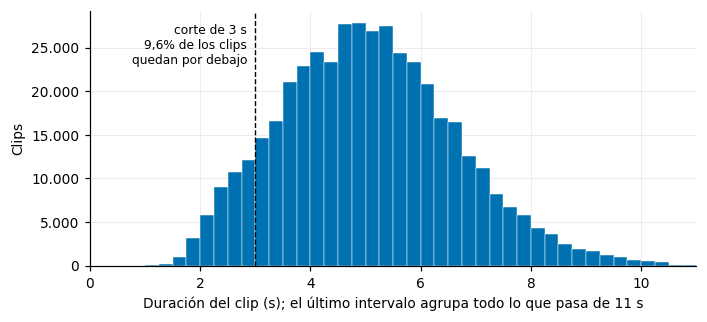

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 3))
limite = np.ceil(df["dur_s"].quantile(0.999))
bins = np.arange(0, limite + 0.25, 0.25)
ax.hist(df["dur_s"].clip(upper=limite), bins=bins, color=AZUL, edgecolor="white", linewidth=0.3)
ax.axvline(MIN_DURATION_MS / 1000, color="black", linestyle="--", linewidth=0.9)
ax.text(MIN_DURATION_MS / 1000 - 0.15, ax.get_ylim()[1] * 0.95,
        f"corte de {MIN_DURATION_MS / 1000:g} s\n{corto.mean():.1%} de los clips\nquedan por debajo".replace(".", ","),
        va="top", ha="right", fontsize=8)
ax.set_xlim(0, limite)
ax.set_xlabel(f"Duración del clip (s); el último intervalo agrupa todo lo que pasa de {limite:g} s")
ax.set_ylabel("Clips")
ax.xaxis.set_major_formatter(coma)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))
fig.tight_layout()
guardar(fig, "duracion_clips")

**Lectura**

- **[Dato]** La mediana es 4,99 s y el 90 % central de los clips va de 2,57 s a 7,82 s (máximo:
  22,6 s). El 9,6 % de los clips (42.068, unas 29 h) dura menos de 3 s.
- **[Interpretación]** El corte de 3 s quita la cola corta de la distribución, no su centro. Buena parte
  de esa cola son palabras sueltas del segmento *Benchmark* (sección 7). Un clip típico dura unos 5 s.

## 4. Clips por hablante: ¿quiénes concentran el corpus?

En Common Voice cada `client_id` es una cuenta (o sesión anónima), que aquí se toma como una persona.
Ese supuesto ya está declarado como limitación: una persona puede tener varias cuentas, y una cuenta
compartida mezclaría voces.

In [9]:
def valor_unico(valores):
    """Metadato de un hablante: su único valor no vacío, 'sin_dato' o 'conflicto' si declara varios."""
    etiquetas = {v.strip() for v in valores if v and v.strip()}
    if not etiquetas:
        return "sin_dato"
    if len(etiquetas) > 1:
        return "conflicto"
    return next(iter(etiquetas))


hablantes = df.groupby("client_id").agg(
    clips=("path", "size"),
    horas=("dur_s", lambda s: s.sum() / 3600),
    dur_media_s=("dur_s", "mean"),
    genero=("gender", valor_unico),
    edad=("age", valor_unico),
    estrato=("accents", assign_stratum),   # misma regla del pipeline (antes de filtros)
).sort_values("clips", ascending=False)
hablantes["clips"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(1).to_frame("clips por hablante")

,clips por hablante
count,17670.0
mean,24.9
std,391.9
min,1.0
25%,3.0
50%,5.0
75%,9.0
90%,23.0
99%,215.9
max,36148.0


In [10]:
cortes = [0, 1, 4, 9, 49, 99, 999, np.inf]
etiquetas = ["1", "2–4", "5–9", "10–49", "50–99", "100–999", "1000 o más"]
grupo = pd.cut(hablantes["clips"], bins=cortes, labels=etiquetas)
tabla_grupos = hablantes.groupby(grupo, observed=False).agg(hablantes=("clips", "size"), clips=("clips", "sum"))
tabla_grupos["% hablantes"] = (100 * tabla_grupos["hablantes"] / len(hablantes)).round(1)
tabla_grupos["% clips"] = (100 * tabla_grupos["clips"] / len(df)).round(1)
tabla_grupos.index.name = "clips grabados"
tabla_grupos

,hablantes,clips,% hablantes,% clips
clips grabados,,,,
1,2202,2202,12.5,0.5
2–4,6282,20152,35.6,4.6
5–9,5058,29766,28.6,6.8
10–49,3332,65342,18.9,14.9
50–99,399,27479,2.3,6.3
100–999,344,85570,1.9,19.5
1000 o más,53,208714,0.3,47.5


In [11]:
# Concentración: qué parte del corpus graban los hablantes más activos.
clips_ordenados = hablantes["clips"].to_numpy()          # ya de mayor a menor
acumulado = np.cumsum(clips_ordenados) / clips_ordenados.sum()
n = len(clips_ordenados)
filas = {}
for etiqueta, k in [("1 hablante", 1), ("10 hablantes", 10), ("100 hablantes", 100),
                    ("1 % de los hablantes", int(round(0.01 * n))), ("10 % de los hablantes", int(round(0.10 * n)))]:
    filas[f"Top {etiqueta} (k = {k})"] = round(100 * acumulado[k - 1], 1)
concentracion = pd.Series(filas, name="% de los clips validados").to_frame()

# Índice de Gini de los clips por hablante (0 = todos graban lo mismo, 1 = uno lo graba todo).
x = np.sort(clips_ordenados)
gini = (2 * np.sum(np.arange(1, n + 1) * x) / (n * x.sum())) - (n + 1) / n
print(f"Gini de clips por hablante: {gini:.3f}")
concentracion

Gini de clips por hablante: 0.837


,% de los clips validados
Top 1 hablante (k = 1),8.2
Top 10 hablantes (k = 10),28.8
Top 100 hablantes (k = 100),54.4
Top 1 % de los hablantes (k = 177),59.9
Top 10 % de los hablantes (k = 1767),80.4


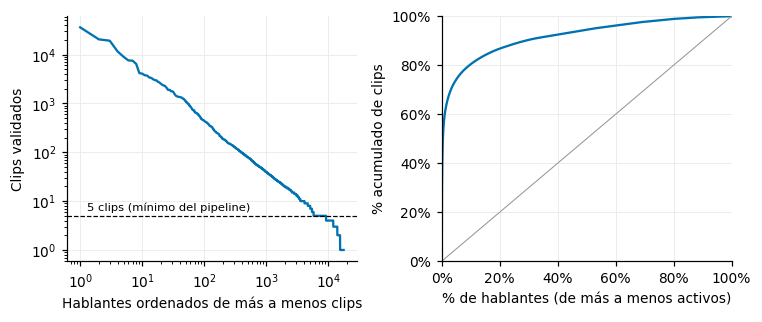

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3))

# Izquierda: rango vs. clips en escala log-log (cola larga).
ax1.loglog(np.arange(1, n + 1), clips_ordenados, color=AZUL, linewidth=1.5)
ax1.axhline(CLIPS_PER_SPEAKER, color="black", linestyle="--", linewidth=0.8)
ax1.text(1.3, CLIPS_PER_SPEAKER * 1.25, f"{CLIPS_PER_SPEAKER} clips (mínimo del pipeline)", fontsize=7.5)
ax1.set_xlabel("Hablantes ordenados de más a menos clips")
ax1.set_ylabel("Clips validados")

# Derecha: curva de concentración (proporción acumulada de clips).
ax2.plot(100 * np.arange(1, n + 1) / n, 100 * acumulado, color=AZUL, linewidth=1.5)
ax2.plot([0, 100], [0, 100], color="0.6", linewidth=0.7)
ax2.set_xlabel("% de hablantes (de más a menos activos)")
ax2.set_ylabel("% acumulado de clips")
ax2.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax2.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax2.set_xlim(0, 100); ax2.set_ylim(0, 100)
fig.tight_layout()
guardar(fig, "concentracion_hablantes")

### Los 20 hablantes con más clips

El `client_id` es un hash. Se muestran solo sus primeros 10 caracteres, suficientes para identificarlo
dentro del corpus.

In [13]:
top20 = hablantes.head(20).copy()
top20.insert(0, "id", top20.index.str[:10])
top20["% del corpus"] = (100 * top20["clips"] / len(df)).round(2)
top20["horas"] = top20["horas"].round(1)
top20["dur_media_s"] = top20["dur_media_s"].round(2)
top20.reset_index(drop=True).rename_axis("puesto").rename(index=lambda i: i + 1)

,id,clips,horas,dur_media_s,genero,edad,estrato,% del corpus
puesto,,,,,,,,
1,a97730f86f,36148,47.4,4.73,male_masculine,sixties,espana_sur,8.23
2,4513134730,20507,27.1,4.76,female_feminine,twenties,sin_dato,4.67
3,e12fff4757,19240,27.5,5.14,male_masculine,conflicto,espana_norte,4.38
4,0708583b47,11638,14.8,4.59,male_masculine,twenties,mexico,2.65
5,906e096993,9035,11.4,4.53,male_masculine,twenties,mexico,2.06
6,1e27ca7ffa,7582,8.1,3.84,male_masculine,twenties,mexico,1.73
7,99b4a9337b,7505,11.4,5.48,female_feminine,twenties,mexico,1.71
8,e419ac13f8,6452,8.2,4.59,male_masculine,twenties,sin_dato,1.47
9,0ae6020868,4176,6.3,5.46,female_feminine,twenties,sin_dato,0.95


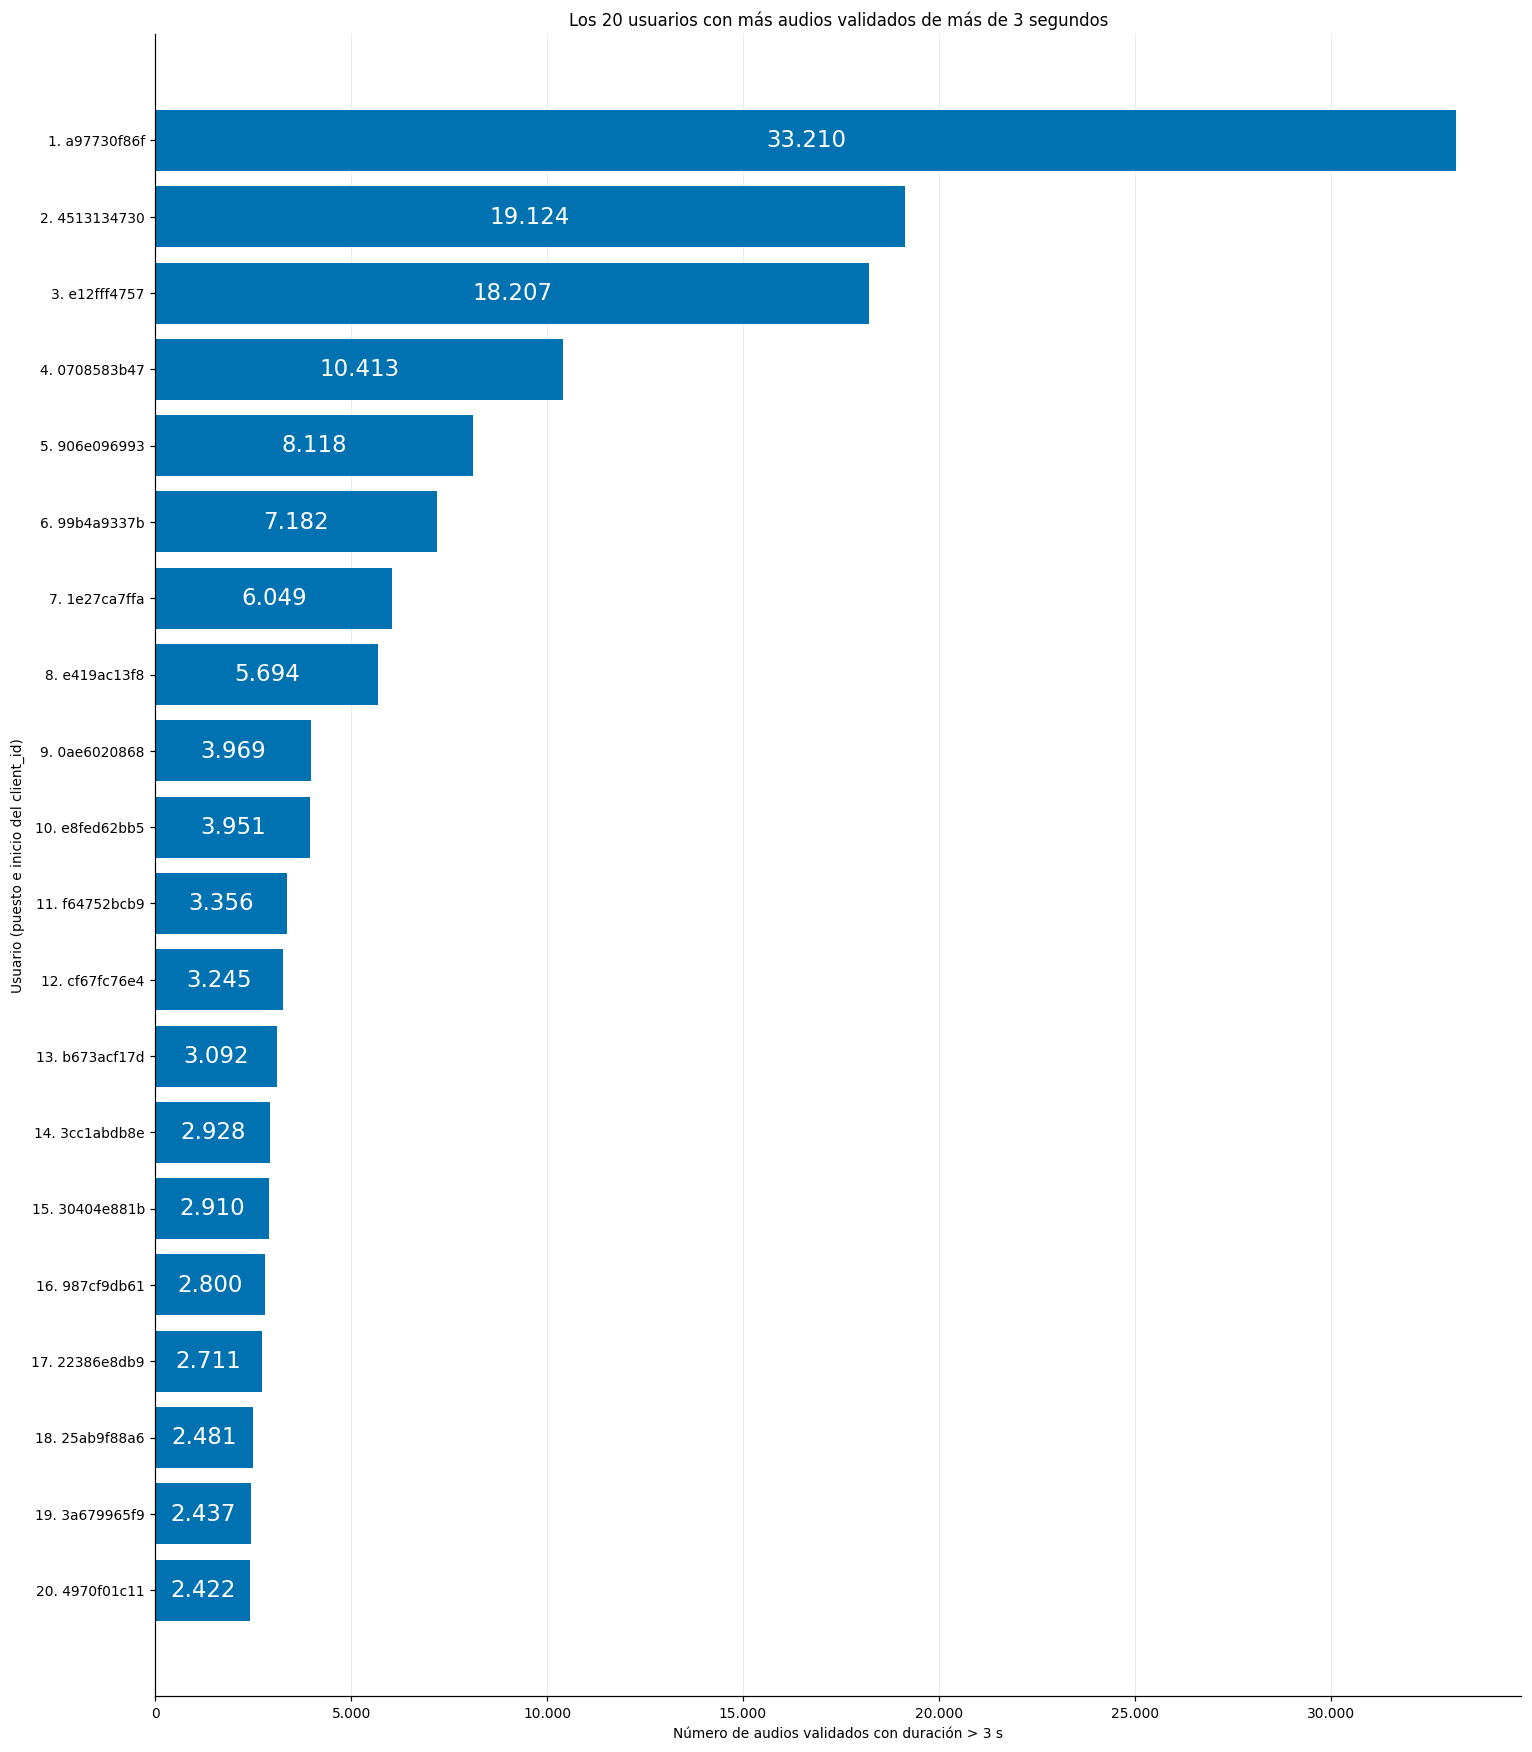

In [38]:
# Los 20 usuarios con más audios validados de duración estrictamente mayor a 3 segundos.
audios_mayores_3s = df.loc[df["duration_ms"] > 3000]
clips_por_usuario = audios_mayores_3s.groupby("client_id").size().sort_values(ascending=False).head(20)
puestos = np.arange(1, len(clips_por_usuario) + 1)

fig, ax = plt.subplots(figsize=(14, 16))
barras = ax.barh(puestos, clips_por_usuario.to_numpy(), color=AZUL)
ax.bar_label(barras, labels=[f"{v:,}".replace(",", ".") for v in clips_por_usuario],
             label_type="center", color="white", fontsize=15)
ax.set_yticks(puestos, [f"{p}. {usuario[:10]}" for p, usuario in zip(puestos, clips_por_usuario.index)])
ax.invert_yaxis()
ax.set_title(f"Los {len(clips_por_usuario)} usuarios con más audios validados de más de 3 segundos")
ax.set_xlabel("Número de audios validados con duración > 3 s")
ax.set_ylabel("Usuario (puesto e inicio del client_id)")
formato_miles = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))
ax.xaxis.set_major_formatter(formato_miles)
ax.grid(axis="y", visible=False)
fig.tight_layout()
guardar(fig, "clips_por_usuario_validados_mayores_3s")
plt.show()

**Lectura**

- **[Dato]** La mediana es de 5 clips por hablante, y el 12,5 % de los hablantes grabó un solo clip. En
  el otro extremo, **53 hablantes con 1.000 clips o más aportan el 47,5 % del corpus**. El hablante más
  activo tiene 36.148 clips (47 h, el 8,2 % del total). El 1 % más activo aporta el 59,9 % de los clips
  y el índice de Gini es 0,837.
- **[Interpretación]** El corpus está muy concentrado. Si los clips de evaluación se eligieran al azar,
  sin mirar quién los grabó, los resultados medirían en la práctica a unas pocas voces. Esto justifica
  muestrear **por hablante**, con 5 clips por persona, como hace `build_subset.py`: cada hablante pesa
  lo mismo en el EER y en el WER.

## 5. Metadatos demográficos (autorreportados)

Género, edad y acento los declara cada persona, y declararlos es opcional. Se asignan **por hablante**
con la misma lógica que el estrato: el único valor no vacío que declara; `sin_dato` si no declara
ninguno; `conflicto` si declara valores distintos en clips distintos.

In [14]:
GENERO = {"male_masculine": "Masculino", "female_feminine": "Femenino",
          "do_not_wish_to_say": "Prefiere no decir", "sin_dato": "Sin dato", "conflicto": "Conflicto"}
EDAD_ORDEN = ["teens", "twenties", "thirties", "fourties", "fifties", "sixties",
              "seventies", "eighties", "nineties", "conflicto", "sin_dato"]
EDAD = {"teens": "10–19", "twenties": "20–29", "thirties": "30–39", "fourties": "40–49",
        "fifties": "50–59", "sixties": "60–69", "seventies": "70–79", "eighties": "80–89",
        "nineties": "90–99", "conflicto": "Conflicto", "sin_dato": "Sin dato"}

cobertura = pd.DataFrame({
    "% hablantes que lo declaran": [
        100 * (hablantes[c] != "sin_dato").mean() for c in ["genero", "edad", "estrato"]],
    "% clips con el dato": [
        100 * (df[c].str.strip() != "").mean() for c in ["gender", "age", "accents"]],
}, index=["Género", "Edad", "Acento"]).round(1)
cobertura

,% hablantes que lo declaran,% clips con el dato
Género,28.8,80.4
Edad,29.6,80.8
Acento,24.9,67.5


hablantes
género Sin dato       12584
       Masculino       3668
       Femenino        1418
edad   10–19            565
       20–29           2328
       30–39           1036
       40–49            731
       50–59            419
       60–69            124
       70–79             16
       80–89              3
       90–99              4
       Conflicto          4
       Sin dato       12440

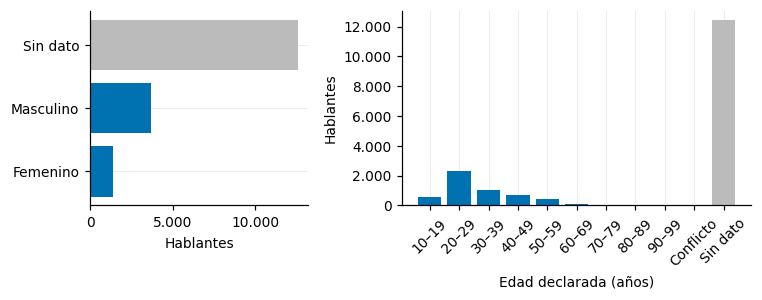

In [15]:
genero_h = hablantes["genero"].map(GENERO).value_counts()
edad_h = hablantes["edad"].value_counts().reindex(EDAD_ORDEN).dropna().rename(index=EDAD)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 2.8), gridspec_kw={"width_ratios": [1, 1.6]})
def color_dato(etiquetas):
    """Gris para 'Sin dato' y 'Conflicto', azul para los valores declarados."""
    return [GRIS if e in ("Sin dato", "Conflicto") else AZUL for e in etiquetas]

miles = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))
ax1.barh(genero_h.index[::-1], genero_h.values[::-1], color=color_dato(genero_h.index[::-1]))
ax1.set_xlabel("Hablantes")
ax1.xaxis.set_major_formatter(miles)
ax2.bar(edad_h.index, edad_h.values, color=color_dato(edad_h.index))
ax2.yaxis.set_major_formatter(miles)
ax2.set_ylabel("Hablantes")
ax2.set_xlabel("Edad declarada (años)")
ax2.tick_params(axis="x", rotation=45)
for ax in (ax1, ax2):
    ax.grid(axis="y" if ax is ax2 else "x")
fig.tight_layout()
guardar(fig, "demografia_hablantes")
pd.concat({"género": genero_h, "edad": edad_h}).to_frame("hablantes")

In [16]:
# Género por edad, solo entre quienes declaran ambos.
declarados = hablantes[(hablantes["genero"] != "sin_dato") & (hablantes["edad"] != "sin_dato")]
pd.crosstab(declarados["edad"].map(EDAD), declarados["genero"].map(GENERO), margins=True,
            margins_name="Total").reindex([EDAD[e] for e in EDAD_ORDEN if EDAD[e] in
                                           set(declarados["edad"].map(EDAD))] + ["Total"])

genero,Femenino,Masculino,Total
edad,,,
10–19,194,354,548
20–29,651,1592,2243
30–39,248,764,1012
40–49,165,549,714
50–59,116,289,405
60–69,31,91,122
70–79,3,11,14
80–89,1,2,3
90–99,0,1,1


**Lectura**

- **[Dato]** Solo el 28,8 % de los hablantes declara su género, pero esos hablantes aportan el 80,4 % de
  los clips: quienes graban mucho suelen completar su perfil. Entre quienes lo declaran hay 3.668 hombres
  y 1.418 mujeres (72 % y 28 %). Ningún hablante tiene género en conflicto entre clips, y solo 4 tienen
  la edad en conflicto. El grupo de edad más numeroso es el de 20–29 años.
- **[Interpretación]** Las voces del corpus son sobre todo masculinas y jóvenes, y los resultados de la
  tesis heredan ese sesgo. Un análisis por género tendrá muchas menos mujeres, con intervalos más
  anchos. Esto debe declararse como limitación.

## 6. Acentos y estratificación

`accents` es texto: la mayoría elige una opción de la lista de Common Voice, pero también hay texto
libre y combinaciones separadas por `|`. `assign_stratum` (en `scripts/common_voice_strata.py`) lleva
cada hablante a uno de los 9 estratos de acento, a `sin_dato` o a `otro`.

In [17]:
# Etiquetas de acento crudas, contadas por hablante (un hablante cuenta una vez por etiqueta).
etiquetas_h = (df.loc[df["accents"].str.strip() != "", ["client_id", "accents"]]
               .drop_duplicates()["accents"].value_counts())
print(f"Etiquetas de acento distintas: {len(etiquetas_h)}")
etiquetas_h.head(15).to_frame("hablantes")

Etiquetas de acento distintas: 114


,hablantes
accents,
México,1082
"Andino-Pacífico: Colombia, Perú, Ecuador, oeste de Bolivia y Venezuela andina",692
"España: Norte peninsular (Asturias, Castilla y León, Cantabria, País Vasco, Navarra, Aragón, La Rioja, Guadalajara, Cuenca)",463
"Caribe: Cuba, Venezuela, Puerto Rico, República Dominicana, Panamá, Colombia caribeña, México caribeño, Costa del golfo de México",418
"Rioplatense: Argentina, Uruguay, este de Bolivia, Paraguay",415
"España: Centro-Sur peninsular (Madrid, Toledo, Castilla-La Mancha)",347
América central,287
"Chileno: Chile, Cuyo",216
"España: Sur peninsular (Andalucia, Extremadura, Murcia)",186


In [18]:
# Hablantes que mencionan Colombia explícitamente en texto libre (además de las dos opciones
# estándar de la lista, que ya incluyen la palabra "Colombia" junto a otros países).
OPCIONES_CON_COLOMBIA = {etiqueta for etiqueta in ACCENT_TO_STRATUM if "Colombia" in etiqueta}


def menciona_colombia(etiqueta):
    partes = [p for p in etiqueta.split("|") if p not in OPCIONES_CON_COLOMBIA]
    return any(clave in p.lower() for p in partes for clave in ("colomb", "bogot", "medell", "paisa"))


colombia = df.loc[df["accents"].apply(menciona_colombia), ["client_id", "accents"]].drop_duplicates()
print("Hablantes con mención explícita a Colombia:", colombia["client_id"].nunique())
colombia["accents"].value_counts().to_frame("hablantes")

Hablantes con mención explícita a Colombia: 11


,hablantes
accents,
"Andino-Pacífico: Colombia, Perú, Ecuador, oeste de Bolivia y Venezuela andina|Bogotá",1
"Andino-Pacífico: Colombia, Perú, Ecuador, oeste de Bolivia y Venezuela andina|Bogota, Colombia",1
Acento de Bogotá|Español masculino del interior de Colombia.,1
neutro de colombia|español sin acentos y algo neutro de colombia,1
Acento neutro|Bogotá: Colombia,1
"Andino-Pacífico: Colombia, Perú, Ecuador, oeste de Bolivia y Venezuela andina|Colombia: Santander",1
"colombia|Cúcuta, Norte de Santander",1
Colombia: Valle del Cauca,1
Colombian Accent,1


In [19]:
# Estratos sobre TODO validated (sin filtros), por hablante.
por_estrato = hablantes.groupby("estrato").agg(hablantes=("clips", "size"), clips=("clips", "sum"),
                                             horas=("horas", "sum"))
por_estrato["% clips"] = (100 * por_estrato["clips"] / len(df)).round(1)
por_estrato["clips por hablante (mediana)"] = hablantes.groupby("estrato")["clips"].median()
por_estrato["horas"] = por_estrato["horas"].round(1)
por_estrato.sort_values("hablantes", ascending=False)

,hablantes,clips,horas,% clips,clips por hablante (mediana)
estrato,,,,,
sin_dato,13277,142549,204.2,32.5,4.0
mexico,1082,141900,194.1,32.3,9.0
andino_pacifico,692,17590,26.1,4.0,8.0
espana_norte,463,40688,57.7,9.3,8.0
caribe,418,10063,15.7,2.3,6.0
rioplatense,415,13716,20.4,3.1,8.0
espana_centro_sur,347,11236,15.8,2.6,10.0
america_central,287,6952,10.8,1.6,9.0
otro,287,4417,6.0,1.0,4.0


### Embudo del pipeline: del corpus a los hablantes elegibles

Se reproduce `build_subset.py` paso a paso: (1) quitar los clips de menos de 3 s, (2) quedarse con
los hablantes que conservan al menos 5 clips, y (3) asignar el estrato con las etiquetas de los clips
que quedaron, que es lo que hace `group_by_stratum`. El estrato **más pequeño** de los 10 muestreados
fija el máximo **K** de hablantes por estrato que permite un diseño balanceado.

In [20]:
df_ok = df[df["duration_ms"].notna() & (df["duration_ms"] >= MIN_DURATION_MS) & (df["client_id"] != "")]
clips_ok = df_ok.groupby("client_id").size()
elegibles_ids = clips_ok.index[clips_ok >= CLIPS_PER_SPEAKER]
estrato_elegibles = (df_ok[df_ok["client_id"].isin(elegibles_ids)]
                     .groupby("client_id")["accents"].agg(assign_stratum))

embudo = pd.DataFrame({
    "1. hablantes en validated": hablantes["estrato"].value_counts(),
    f"2. con algún clip >= {MIN_DURATION_MS / 1000:g} s": hablantes.loc[clips_ok.index, "estrato"].value_counts(),
    f"3. elegibles (>= {CLIPS_PER_SPEAKER} clips >= {MIN_DURATION_MS / 1000:g} s)": estrato_elegibles.value_counts(),
}).fillna(0).astype(int)
embudo["¿se muestrea?"] = embudo.index.isin(STRATA)
embudo = embudo.sort_values(embudo.columns[2], ascending=False)

k_max = embudo.loc[STRATA, embudo.columns[2]].min()
limitante = embudo.loc[STRATA, embudo.columns[2]].idxmin()
print(f"K máximo balanceado: {k_max} hablantes por estrato (lo limita '{limitante}')")
print(f"Total de hablantes elegibles: {len(elegibles_ids):,}")
embudo

K máximo balanceado: 134 hablantes por estrato (lo limita 'chileno')
Total de hablantes elegibles: 7,696


,1. hablantes en validated,2. con algún clip >= 3 s,3. elegibles (>= 5 clips >= 3 s),¿se muestrea?
sin_dato,13277,12378,5014,True
mexico,1082,1063,675,True
andino_pacifico,692,678,409,True
espana_norte,463,459,287,True
rioplatense,415,409,270,True
caribe,418,406,241,True
espana_centro_sur,347,344,235,True
america_central,287,286,172,True
espana_sur,186,185,137,True
chileno,216,213,134,True


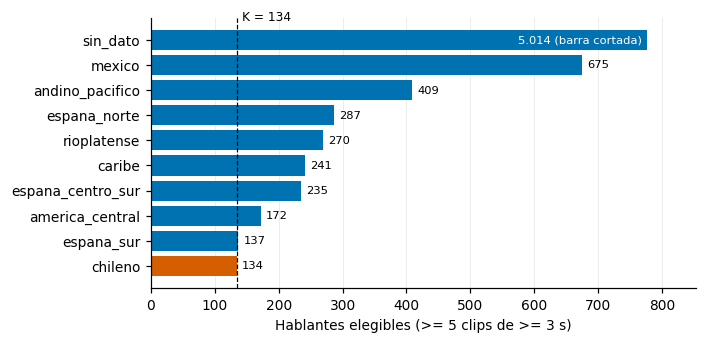

In [21]:
elegibles_estrato = embudo.loc[STRATA, embudo.columns[2]].sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3.2))
colores = [NARANJA if s == limitante else AZUL for s in elegibles_estrato.index]
# Eje lineal cortado: 'sin_dato' es mucho más grande que el resto y se marca como barra truncada.
tope = 1.15 * elegibles_estrato.drop(SIN_DATO).max()
ax.barh(elegibles_estrato.index, elegibles_estrato.clip(upper=tope).values, color=colores)
ax.axvline(k_max, color="black", linestyle="--", linewidth=0.8)
ax.text(k_max + 8, len(elegibles_estrato) - 0.35, f"K = {k_max}", fontsize=8, va="bottom")
for y, v in enumerate(elegibles_estrato.values):
    truncada = v > tope
    ax.text(min(v, tope) + (-8 if truncada else 8), y, f"{v:,}".replace(",", ".") + (" (barra cortada)" if truncada else ""),
            va="center", ha="right" if truncada else "left", fontsize=7.5, color="white" if truncada else "black")
ax.set_xlim(0, tope * 1.1)
ax.set_xlabel(f"Hablantes elegibles (>= {CLIPS_PER_SPEAKER} clips de >= {MIN_DURATION_MS / 1000:g} s)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
guardar(fig, "hablantes_elegibles_estrato")

In [22]:
# Género de los hablantes elegibles, por estrato (en % de los hablantes del estrato).
eleg = hablantes.loc[elegibles_ids].assign(estrato=estrato_elegibles)
eleg = eleg[eleg["estrato"].isin(STRATA)]
genero_estrato = pd.crosstab(eleg["estrato"], eleg["genero"].map(GENERO), normalize="index").mul(100).round(1)
genero_estrato = genero_estrato.reindex(columns=[c for c in ["Masculino", "Femenino", "Prefiere no decir",
                                                             "Conflicto", "Sin dato"] if c in genero_estrato])
genero_estrato.loc[elegibles_estrato.index[::-1]]

genero,Masculino,Femenino,Sin dato
sin_dato,8.5,4.3,87.1
mexico,65.9,32.0,2.1
andino_pacifico,75.8,20.8,3.4
espana_norte,68.3,28.2,3.5
rioplatense,68.1,29.3,2.6
caribe,71.8,22.8,5.4
espana_centro_sur,71.1,26.4,2.6
america_central,69.8,27.9,2.3
espana_sur,76.6,21.9,1.5
chileno,73.9,23.1,3.0


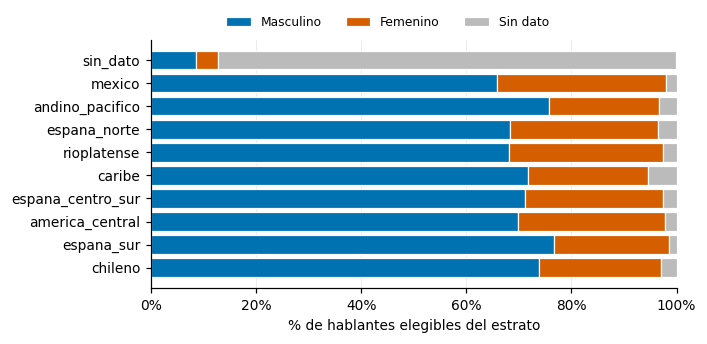

In [23]:
orden = elegibles_estrato.index
colores_genero = {"Masculino": AZUL, "Femenino": NARANJA, "Sin dato": GRIS}
fig, ax = plt.subplots(figsize=(6.5, 3.2))
izquierda = np.zeros(len(orden))
for categoria in genero_estrato.columns:
    valores = genero_estrato.loc[orden, categoria].to_numpy()
    ax.barh(orden, valores, left=izquierda, color=colores_genero.get(categoria, VERDE),
            label=categoria, edgecolor="white", linewidth=0.8)
    izquierda += valores
ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_xlim(0, 100)
ax.set_xlabel("% de hablantes elegibles del estrato")
ax.legend(frameon=False, ncol=len(genero_estrato.columns), loc="lower center",
          bbox_to_anchor=(0.45, 1.0), fontsize=8)
ax.grid(axis="y", visible=False)
fig.tight_layout()
guardar(fig, "genero_por_estrato")

**Lectura**

- **[Dato]** Hay 114 etiquetas de acento distintas. Después de los filtros quedan 7.696 hablantes
  elegibles, 7.574 de ellos en los 10 estratos que se muestrean. El estrato más pequeño es `chileno`, con
  134 elegibles, y ese número fija **K = 134**. Le sigue `espana_sur`, con 137, ya casi en el límite.
  "España: Islas Canarias" (167 hablantes con esa etiqueta) no es un estrato del diseño y cae en `otro`.
- **[Dato]** En los estratos con acento declarado, entre el 66 % y el 77 % de los hablantes son hombres.
  En `sin_dato`, el 87 % tampoco declara género.
- **[Interpretación]** K = 134 es el máximo que permite un diseño balanceado con estos filtros. En
  `chileno` entran todos los elegibles y en `espana_sur` casi todos (98 %). En esos dos estratos el
  subconjunto **es** la población elegible y no hay margen para remuestrear con otra semilla.
- **[Interpretación] Relevante para el contexto colombiano:** Common Voice no tiene una opción
  "colombiano". Las voces colombianas quedan repartidas entre `andino_pacifico` y `caribe`, mezcladas
  con las de otros países, y solo 11 hablantes mencionan Colombia en texto libre. Por eso la evaluación
  no puede aislar el acento colombiano: `andino_pacifico` es la mejor aproximación disponible, y esto va
  como limitación.

## 7. El texto leído

El texto importa por dos razones. Las frases largas dan clips largos, y las cifras y los nombres propios
son la mayor fuente de errores de Whisper en la evaluación de WER. Las mayúsculas en medio de la frase
se usan como **aproximación** (no como medida exacta) a los nombres propios.

In [24]:
texto = df[["client_id", "sentence_id", "sentence", "dur_s"]].copy()
palabras = texto["sentence"].str.split()
texto["palabras"] = palabras.str.len()
texto["caracteres"] = texto["sentence"].str.len()
texto["palabras_por_s"] = texto["palabras"] / texto["dur_s"]
texto["tiene_cifras"] = texto["sentence"].str.contains(r"\d", regex=True)
# Palabras con mayúscula inicial que no abren la frase (aprox. nombres propios y siglas).
texto["mayus_internas"] = palabras.apply(lambda ws: sum(w[:1].isupper() for w in ws[1:]))

texto["benchmark"] = df["segment"] == "Benchmark"
lecturas_por_frase = df["sentence_id"].value_counts()
resumen_texto = pd.Series({
    "Palabras por frase (mediana)": texto["palabras"].median(),
    "Palabras por frase (p95)": texto["palabras"].quantile(0.95),
    "Caracteres por frase (mediana)": texto["caracteres"].median(),
    "Frases distintas": len(lecturas_por_frase),
    "% de frases leídas por más de un clip": round(100 * (lecturas_por_frase > 1).mean(), 2),
    "Máximo de lecturas de una misma frase": lecturas_por_frase.max(),
    "% de clips con cifras (0–9)": round(100 * texto["tiene_cifras"].mean(), 2),
    "% de clips con alguna mayúscula interna": round(100 * (texto["mayus_internas"] > 0).mean(), 1),
    "Velocidad de lectura (palabras/s, mediana)": round(texto["palabras_por_s"].median(), 2),
}, name="valor", dtype=object)
resumen_texto.to_frame()

,valor
Palabras por frase (mediana),10.0
Palabras por frase (p95),14.0
Caracteres por frase (mediana),60.0
Frases distintas,391420
% de frases leídas por más de un clip,2.68
Máximo de lecturas de una misma frase,1759
% de clips con cifras (0–9),0.0
% de clips con alguna mayúscula interna,40.2
"Velocidad de lectura (palabras/s, mediana)",1.88


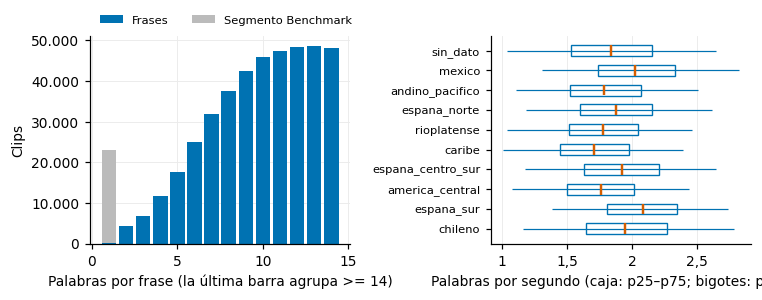

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 2.8))
max_pal = int(texto["palabras"].quantile(0.999))
pal = texto["palabras"].clip(upper=max_pal)
ax1.hist([pal[~texto["benchmark"]], pal[texto["benchmark"]]], bins=np.arange(0.5, max_pal + 1.5, 1),
         stacked=True, color=[AZUL, GRIS], label=["Frases", "Segmento Benchmark"], rwidth=0.85)
ax1.legend(frameon=False, fontsize=7.5, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
ax1.set_xlabel(f"Palabras por frase (la última barra agrupa >= {max_pal})")
ax1.set_ylabel("Clips")
ax1.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", ".")))

# Velocidad de lectura de los elegibles, por estrato (estrato del pipeline).
vel = texto.loc[df_ok.index].merge(estrato_elegibles.rename("estrato"), left_on="client_id", right_index=True)
orden_vel = list(elegibles_estrato.index)
# Diagrama de caja dibujado a mano (evita diferencias entre versiones de matplotlib):
# caja = cuartiles 1 y 3, línea naranja = mediana, bigotes = p5 y p95.
for y, s in enumerate(orden_vel):
    v = vel.loc[vel["estrato"] == s, "palabras_por_s"]
    p5, q1, med, q3, p95 = v.quantile([0.05, 0.25, 0.5, 0.75, 0.95])
    ax2.hlines(y, p5, p95, color=AZUL, linewidth=0.8)
    ax2.barh(y, q3 - q1, left=q1, height=0.55, color="white", edgecolor=AZUL, linewidth=0.9)
    ax2.vlines(med, y - 0.27, y + 0.27, color=NARANJA, linewidth=1.6)
ax2.set_yticks(range(len(orden_vel)), orden_vel)
ax2.set_xlabel("Palabras por segundo (caja: p25–p75; bigotes: p5–p95)")
ax2.xaxis.set_major_formatter(coma)
ax2.tick_params(axis="y", labelsize=7.5)
ax2.grid(axis="y", visible=False)
fig.tight_layout()
guardar(fig, "texto_y_velocidad")

In [26]:
# El segmento 'Benchmark': palabras sueltas (cifras, sí/no, "Hey Firefox").
bench = df[df["segment"] == "Benchmark"]
print(f"Clips Benchmark: {len(bench):,} | hablantes: {bench['client_id'].nunique():,} | "
      f"duración mediana: {bench['dur_s'].median():.2f} s | "
      f"% de menos de {MIN_DURATION_MS / 1000:g} s: {(bench['duration_ms'] < MIN_DURATION_MS).mean():.1%} | "
      f"quedan tras el filtro de duración: {(bench['duration_ms'] >= MIN_DURATION_MS).sum():,}")
display(bench["sentence"].value_counts().head(14).to_frame("clips"))

# Relación entre largo del texto y duración del clip (correlación de Spearman).
rho = texto[["palabras", "dur_s"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman(palabras, duración) = {rho:.3f}")

Clips Benchmark: 23,033 | hablantes: 3,742 | duración mediana: 2.54 s | % de menos de 3 s: 73.9% | quedan tras el filtro de duración: 6,011


,clips
sentence,
siete,1759
no,1726
uno,1710
cuatro,1707
sí,1702
ocho,1689
tres,1687
dos,1685
seis,1685


Spearman(palabras, duración) = 0.734


**Lectura**

- **[Dato]** Las frases tienen una mediana de 10 palabras (máximo 18). Casi todas se leen una sola vez:
  solo el 2,7 % de las frases tiene más de una grabación. **Ningún clip trae cifras (0–9)**, porque los
  números aparecen escritos con letras.
- **[Interpretación]** Las cifras que aparecen en las transcripciones de Whisper no pueden coincidir con
  la referencia sin normalización. Esto justifica pasar los números a palabras en `normalize_final`.
- **[Dato]** El 40 % de los clips tiene alguna palabra con mayúscula dentro de la frase. Es una
  aproximación gruesa a los nombres propios, y coincide con que los nombres propios dominan los errores
  de WER del audio original.
- **[Dato]** El segmento *Benchmark* tiene 23.033 clips de 3.742 hablantes, todos de una sola palabra
  (cifras del cero al nueve, "sí", "no", "Hey", "Firefox"). El 74 % dura menos de 3 s; 6.011 pasan
  el filtro.
- **[Interpretación]** Esos clips son una tarea distinta (palabra suelta) y en el WER cuentan como una
  frase de una palabra. Su peso en el subconjunto es bajo (sección 8).
- **[Dato]** La velocidad mediana es 1,88 palabras/s, y la correlación de Spearman entre palabras y
  duración es 0,73. La velocidad incluye los silencios al inicio y al final del clip, así que **no** es
  la velocidad de articulación.

## 8. ¿Se parece el subconjunto K = 134 al corpus?

`subset_k134.tsv` tiene 134 hablantes por estrato, con 5 clips cada uno. Aquí se comprueba (a) que cada
hablante del subconjunto cae en el estrato que dice el manifiesto, y (b) cómo cambian la duración, el
género y la edad entre los clips elegibles del corpus y el subconjunto. Si el archivo no existe, la
sección se salta.

In [27]:
if SUBSET_PATH.exists():
    subset = leer_tsv(SUBSET_PATH)
    subset["duration_ms"] = subset["duration_ms"].astype(int)
    h_sub = subset.groupby("client_id")["stratum"].agg(lambda s: s.iloc[0])

    # (a) Coherencia con el embudo: elegibles y mismo estrato.
    print("Hablantes en el subconjunto:", h_sub.size, "| clips:", len(subset))
    print("¿Todos son elegibles?        ", bool(h_sub.index.isin(elegibles_ids).all()))
    print("¿Mismo estrato que el embudo?", bool((estrato_elegibles.loc[h_sub.index] == h_sub).all()))
    print("Hablantes por estrato:", h_sub.value_counts().unique())
else:
    subset = None
    print("No se encontró", SUBSET_PATH, "- se salta esta sección.")

Hablantes en el subconjunto: 1340 | clips: 6700
¿Todos son elegibles?         True
¿Mismo estrato que el embudo? True
Hablantes por estrato: [134]


Comparar el subconjunto con **todos** los clips elegibles juntos sería injusto. Esos clips están
dominados por `sin_dato` (5.014 de los 7.574 hablantes) y por unos pocos hablantes con miles de
grabaciones, mientras que el subconjunto toma 134 hablantes por estrato y 5 clips por hablante. Por eso
los elegibles se **ponderan como el diseño**: cada estrato pesa igual, cada hablante pesa igual dentro
de su estrato y cada clip pesa igual dentro de su hablante. Si el muestreo no tiene sesgo, el
subconjunto debe parecerse a esa versión ponderada.

In [28]:
if subset is not None:
    eleg_clips = df_ok[df_ok["client_id"].isin(eleg.index)].copy()
    eleg_clips["estrato"] = eleg_clips["client_id"].map(estrato_elegibles)
    n_clips_h = eleg_clips.groupby("client_id")["path"].transform("size")
    n_hab_e = eleg_clips.groupby("estrato")["client_id"].transform("nunique")
    eleg_clips["peso"] = 1 / (n_clips_h * n_hab_e)
    subset["dur_s"] = subset["duration_ms"] / 1000
    benchmark_paths = set(df.loc[df["segment"] == "Benchmark", "path"])

    def mediana_ponderada(x, w):
        orden_x = np.argsort(x.to_numpy())
        xs, ws = x.to_numpy()[orden_x], w.to_numpy()[orden_x]
        return xs[np.searchsorted(np.cumsum(ws) / ws.sum(), 0.5)]

    def pct_hablantes(ids, estratos, columna, valor):
        # Promedio de los porcentajes de cada estrato: todos los estratos pesan igual.
        return 100 * (hablantes.loc[ids, columna] == valor).groupby(estratos.loc[ids].to_numpy()).mean().mean()

    w_uno = pd.Series(1.0, index=subset.index)
    filas = {
        "duración mediana (s)": (mediana_ponderada(eleg_clips["dur_s"], eleg_clips["peso"]),
                                 subset["dur_s"].median()),
        "% clips de menos de 4 s": (100 * np.average(eleg_clips["dur_s"] < 4, weights=eleg_clips["peso"]),
                                    100 * (subset["dur_s"] < 4).mean()),
        "% clips del segmento Benchmark": (
            100 * np.average(eleg_clips["path"].isin(benchmark_paths), weights=eleg_clips["peso"]),
            100 * subset["path"].isin(benchmark_paths).mean()),
    }
    for nombre, columna, valor in [("% hablantes Masculino", "genero", "male_masculine"),
                                   ("% hablantes Femenino", "genero", "female_feminine"),
                                   ("% hablantes sin género", "genero", "sin_dato"),
                                   ("% hablantes sin edad", "edad", "sin_dato")]:
        filas[nombre] = (pct_hablantes(eleg.index, eleg["estrato"], columna, valor),
                         pct_hablantes(h_sub.index, h_sub, columna, valor))
    comparacion = pd.DataFrame(filas, index=["Esperado (elegibles ponderados)", "Subconjunto K = 134"]).T.round(2)
    display(comparacion)

,Esperado (elegibles ponderados),Subconjunto K = 134
duración mediana (s),5.51,5.54
% clips de menos de 4 s,14.09,13.94
% clips del segmento Benchmark,2.38,2.34
% hablantes Masculino,64.98,64.85
% hablantes Femenino,23.67,24.10
% hablantes sin género,11.34,11.04
% hablantes sin edad,10.10,10.00


In [29]:
if subset is not None:
    # Mismo contraste, estrato por estrato, para el género.
    por_estrato_sub = pd.DataFrame({
        "elegibles": eleg.groupby("estrato").size(),
        "% Masculino (elegibles)": 100 * (eleg["genero"] == "male_masculine").groupby(eleg["estrato"]).mean(),
        "% Masculino (subconjunto)": 100 * (hablantes.loc[h_sub.index, "genero"] == "male_masculine")
                                     .groupby(h_sub.to_numpy()).mean(),
        "% Femenino (elegibles)": 100 * (eleg["genero"] == "female_feminine").groupby(eleg["estrato"]).mean(),
        "% Femenino (subconjunto)": 100 * (hablantes.loc[h_sub.index, "genero"] == "female_feminine")
                                    .groupby(h_sub.to_numpy()).mean(),
    }).round(1)
    por_estrato_sub["% de elegibles que entran"] = (100 * 134 / por_estrato_sub["elegibles"]).round(1)
    display(por_estrato_sub.loc[elegibles_estrato.index[::-1]])

,elegibles,% Masculino (elegibles),% Masculino (subconjunto),% Femenino (elegibles),% Femenino (subconjunto),% de elegibles que entran
sin_dato,5014,8.5,6.7,4.3,5.2,2.7
mexico,675,65.9,66.4,32.0,31.3,19.9
andino_pacifico,409,75.8,78.4,20.8,19.4,32.8
espana_norte,287,68.3,69.4,28.2,28.4,46.7
rioplatense,270,68.1,70.9,29.3,25.4,49.6
caribe,241,71.8,71.6,22.8,25.4,55.6
espana_centro_sur,235,71.1,67.2,26.4,30.6,57.0
america_central,172,69.8,67.2,27.9,30.6,77.9
espana_sur,137,76.6,76.9,21.9,21.6,97.8
chileno,134,73.9,73.9,23.1,23.1,100.0


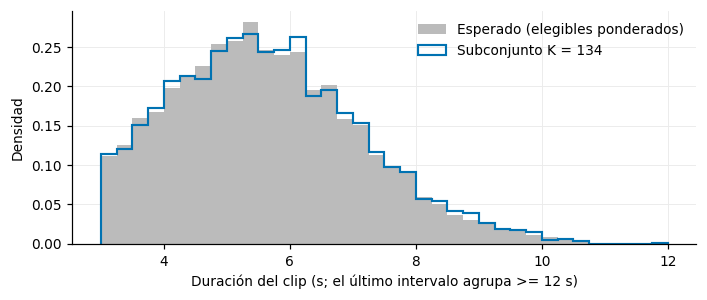

In [30]:
if subset is not None:
    fig, ax = plt.subplots(figsize=(6.5, 2.8))
    bins = np.arange(MIN_DURATION_MS / 1000, 12.25, 0.25)
    ax.hist(eleg_clips["dur_s"].clip(upper=12), bins=bins, weights=eleg_clips["peso"], density=True,
            color=GRIS, label="Esperado (elegibles ponderados)")
    ax.hist(subset["dur_s"].clip(upper=12), bins=bins, density=True, histtype="step",
            color=AZUL, linewidth=1.4, label="Subconjunto K = 134")
    ax.set_xlabel("Duración del clip (s; el último intervalo agrupa >= 12 s)")
    ax.set_ylabel("Densidad")
    ax.xaxis.set_major_formatter(coma)
    ax.legend(frameon=False)
    fig.tight_layout()
    guardar(fig, "duracion_subconjunto_vs_elegibles")

**Lectura**

- **[Dato]** Los 1.340 hablantes del subconjunto son elegibles y caen en el mismo estrato que asigna el
  embudo, así que el notebook reproduce las reglas de `build_subset.py`.
- **[Dato]** Frente a lo esperado según el diseño, la mediana de duración es 5,54 s contra 5,51 s,
  los hombres son 64,9 % contra 65,0 %, las mujeres 24,1 % contra 23,7 %, los hablantes sin género 11,0 %
  contra 11,3 %, y los clips *Benchmark* 2,3 % contra 2,4 %. Estrato por estrato, el género difiere a
  lo sumo unos 4 puntos (`espana_centro_sur` y `rioplatense`).
- **[Interpretación]** No hay señales de sesgo de muestreo: el subconjunto se parece a la población de
  la que se extrajo. Las diferencias por estrato son del tamaño que se espera al sacar 134 hablantes al
  azar (no se probó formalmente). El subconjunto **no** representa las proporciones del corpus
  completo, y no está hecho para eso: por diseño, sobrerrepresenta los acentos minoritarios.

## 9. Resumen para la tesis

In [31]:
resumen = pd.Series({
    "Clips validados": f"{len(df):,}",
    "Horas validadas": f"{df['dur_s'].sum() / 3600:.1f}",
    "Hablantes": f"{hablantes.shape[0]:,}",
    "Duración mediana (s)": f"{df['dur_s'].median():.2f}",
    f"% clips < {MIN_DURATION_MS / 1000:g} s": f"{100 * corto.mean():.1f}",
    "Hablantes con 1 solo clip (%)": f"{100 * (hablantes['clips'] == 1).mean():.1f}",
    "Clips del 1 % de hablantes más activo (%)": concentracion.iloc[3, 0],
    "Gini clips/hablante": f"{gini:.3f}",
    "Hablantes que declaran género (%)": cobertura.loc["Género"].iloc[0],
    "Hablantes elegibles (10 estratos)": f"{len(eleg):,}",
    "K máximo balanceado": f"{k_max} (limita {limitante})",
}, name="valor")
resumen.to_frame()

,valor
Clips validados,"439,225"
Horas validadas,617.5
Hablantes,"17,670"
Duración mediana (s),4.99
% clips < 3 s,9.6
Hablantes con 1 solo clip (%),12.5
Clips del 1 % de hablantes más activo (%),59.9
Gini clips/hablante,0.837
Hablantes que declaran género (%),28.8
Hablantes elegibles (10 estratos),"7,574"


**Para el capítulo de datos de la tesis**

- **[Dato]** Common Voice 26.0 en español, clips validados: 439.225 clips, 617,5 h y 17.670 hablantes.
  La mediana de duración es 5,0 s.
- **[Dato]** La concentración es extrema (Gini 0,84; el 1 % de los hablantes aporta el 60 % de los
  clips). Esto justifica muestrear por hablante.
- **[Dato]** K = 134 es el máximo balanceado; lo limita `chileno`. El subconjunto tiene 1.340 hablantes
  y 6.700 clips, y reproduce la población elegible.

**Limitaciones que salen de este análisis**

1. Los metadatos son autorreportados y en su mayoría faltan: el 71 % de los hablantes no declara género.
2. Hay sesgo masculino (unos 72/28 entre quienes declaran género) y hacia edades de 20–29 años.
3. No hay un estrato colombiano: la mejor aproximación es `andino_pacifico`.
4. `client_id` se toma como una persona.
5. El texto viene de Wikipedia (98 % de las frases, según el README), no de habla telefónica
   espontánea, y el audio no es de canal telefónico.